# ARTI403 – Image Processing

**Name:** Abdulsamad Mousa Yahya Tuhaysha &nbsp;&nbsp; **ID:** 2240001093

---

# **Lab 7(A) - Laplacian Filter**

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)




## Apply Laplacian Filter on Image to get Sharp Image

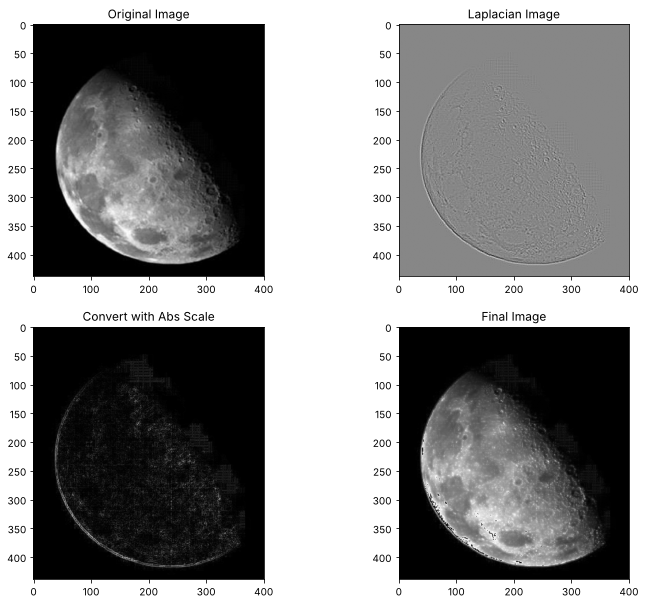

In [2]:

# ================ ( Laplacian Filter ) ===================


# 0. Image file path
imgFile = "images/moon.jpg"

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Alternative kernel: Detects diagonal edges as well
# manual_kernel = np.array([
#     [1,  1,  1],
#     [1, -8,  1],
#     [1,  1,  1]
# ], dtype=np.float32)

# 3. Apply the filter using filter2D
# -1 indicates the output image will have the same depth as the source
# However, for Laplacian, use cv2.CV_64F to avoid clipping negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

finalImage = img + laplacian_abs

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'), plt.title('Final Image')
plt.show()


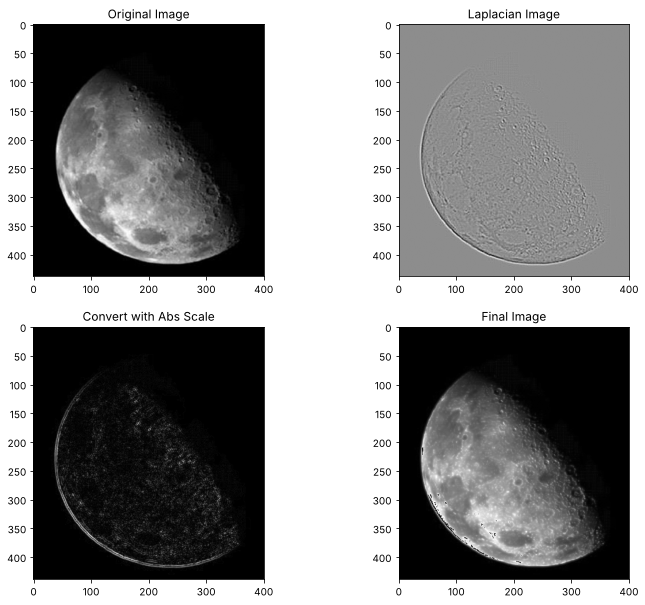

In [3]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
# This prevents the algorithm from picking up tiny details as edges
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm
# Use CV_64F to capture both positive and negative gradients (essential for edges)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplace and origianl Image
finalImage2 = img + laplacian_8bit

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'), plt.title('Final Image')
plt.show()




##

---
# **RGB Part: Laplacian Filter on Colour Images**

The cells above work on grayscale images. Below, the same two methods are applied to an RGB image.

A colour image has three channels (R, G, B). There are two common ways to apply the Laplacian:

1. **Per channel**: run the filter on R, G and B separately and merge them back. `cv2.filter2D`, `cv2.GaussianBlur` and `cv2.Laplacian` already do this automatically when they get a 3-channel image.
2. **Luminance only**: convert to YCrCb, sharpen only the Y (brightness) channel, and convert back. The colour channels stay untouched, so no false colours appear at the edges.

Note: `cv2.imread` loads colour images in **BGR** order, so we convert to RGB before showing them with matplotlib.

Image shape: (300, 451, 3)   dtype: uint8


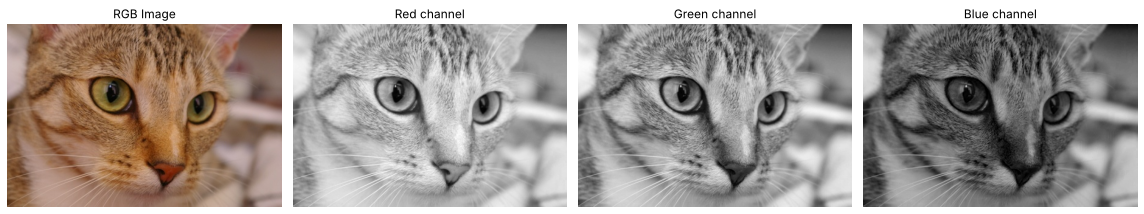

In [4]:
# ================ ( Load RGB image ) ===================
import os

rgbFile = "images/cat.jpg"          # can swap this for any colour pic

# didn't have the pic? just grab the cat from skimage and save it
if not os.path.exists(rgbFile):
    from skimage import data
    cv2.imwrite(rgbFile, cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR))

img_bgr = cv2.imread(rgbFile)                       # opencv reads it as BGR not RGB
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)  # flip to RGB or plt shows the colours wrong

print("Image shape:", img_rgb.shape, "  dtype:", img_rgb.dtype)

# quick look at R, G, B on their own
R, G, B = cv2.split(img_rgb)
plt.figure(figsize=(16, 4))
plt.subplot(141), plt.imshow(img_rgb), plt.title('RGB Image'), plt.axis('off')
plt.subplot(142), plt.imshow(R, cmap='gray'), plt.title('Red channel'), plt.axis('off')
plt.subplot(143), plt.imshow(G, cmap='gray'), plt.title('Green channel'), plt.axis('off')
plt.subplot(144), plt.imshow(B, cmap='gray'), plt.title('Blue channel'), plt.axis('off')
plt.tight_layout()
plt.show()


## Method 1 on RGB: manual Laplacian kernel with `filter2D` (per channel)

Values that wrapped around in img + |lap|: 752


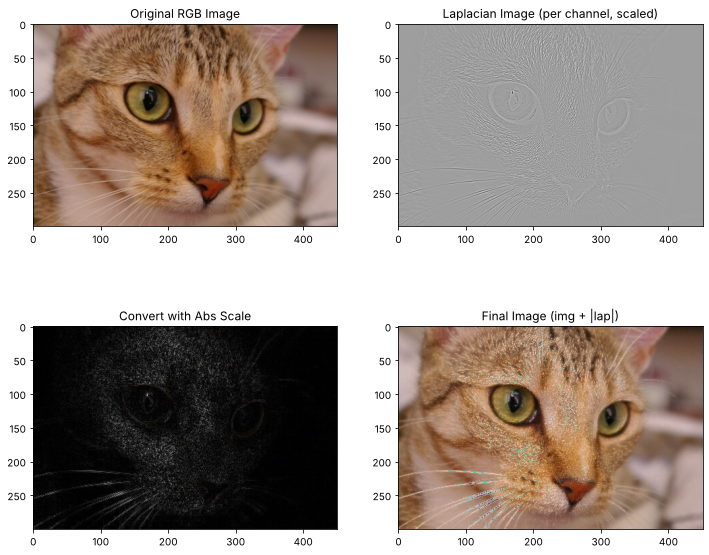

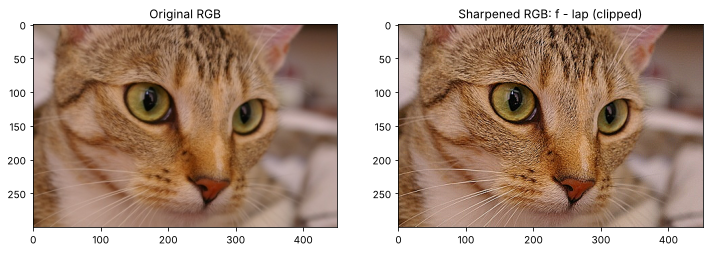

In [5]:
# ================ ( Laplacian Filter - RGB, Method 1 ) ===================

manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# 1. same kernel as before, filter2D just runs it on all 3 channels by itself
laplacian_rgb = cv2.filter2D(img_rgb, cv2.CV_64F, manual_kernel)

# 2. abs + back to uint8
laplacian_rgb_abs = cv2.convertScaleAbs(laplacian_rgb)

# 3. same add as the gray version (careful: uint8 wraps after 255)
finalImage_rgb = img_rgb + laplacian_rgb_abs

# 4. the proper way: f - lap (centre is -4 so we subtract), do it in float then clip
sharp_rgb = np.clip(img_rgb.astype(np.float64) - laplacian_rgb, 0, 255).astype(np.uint8)

# lap has negatives so stretch it to 0-255 just to see it
lap_show = cv2.normalize(laplacian_rgb, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img_rgb), plt.title('Original RGB Image')
plt.subplot(222), plt.imshow(lap_show), plt.title('Laplacian Image (per channel, scaled)')
plt.subplot(223), plt.imshow(laplacian_rgb_abs), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage_rgb), plt.title('Final Image (img + |lap|)')
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(img_rgb), plt.title('Original RGB')
plt.subplot(122), plt.imshow(sharp_rgb), plt.title('Sharpened RGB: f - lap (clipped)')
plt.show()

wrapped = np.sum(img_rgb.astype(int) + laplacian_rgb_abs.astype(int) > 255)
print("Values that wrapped around in img + |lap|:", wrapped)


## Method 2 on RGB: Gaussian blur + `cv2.Laplacian` (per channel)

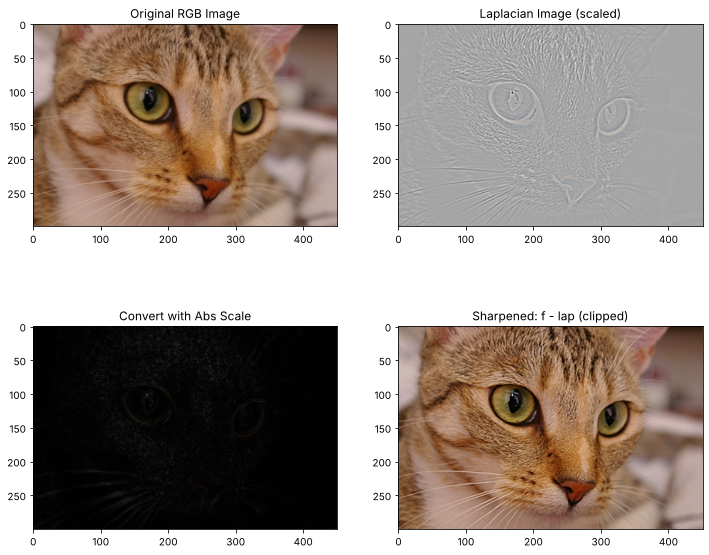

In [6]:
# ================== ( Laplacian Filter - RGB, Method 2 ) ===============

# 1. small blur first so noise doesn't turn into fake edges
blurred_rgb = cv2.GaussianBlur(img_rgb, (3, 3), 0)

# 2. laplacian (works on colour directly)
laplacian2_rgb = cv2.Laplacian(blurred_rgb, cv2.CV_64F)

# 3. back to 8 bit
laplacian2_rgb_8bit = cv2.convertScaleAbs(laplacian2_rgb)

# 4. lab version + my fixed version
finalImage2_rgb = img_rgb + laplacian2_rgb_8bit
sharp2_rgb = np.clip(img_rgb.astype(np.float64) - laplacian2_rgb, 0, 255).astype(np.uint8)

lap2_show = cv2.normalize(laplacian2_rgb, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img_rgb), plt.title('Original RGB Image')
plt.subplot(222), plt.imshow(lap2_show), plt.title('Laplacian Image (scaled)')
plt.subplot(223), plt.imshow(laplacian2_rgb_8bit), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(sharp2_rgb), plt.title('Sharpened: f - lap (clipped)')
plt.show()


## Sharpening only the brightness (YCrCb)

Sharpening R, G and B separately can create thin coloured fringes, because each channel gets a slightly different correction. Doing the Laplacian on the Y (luminance) channel only avoids that.

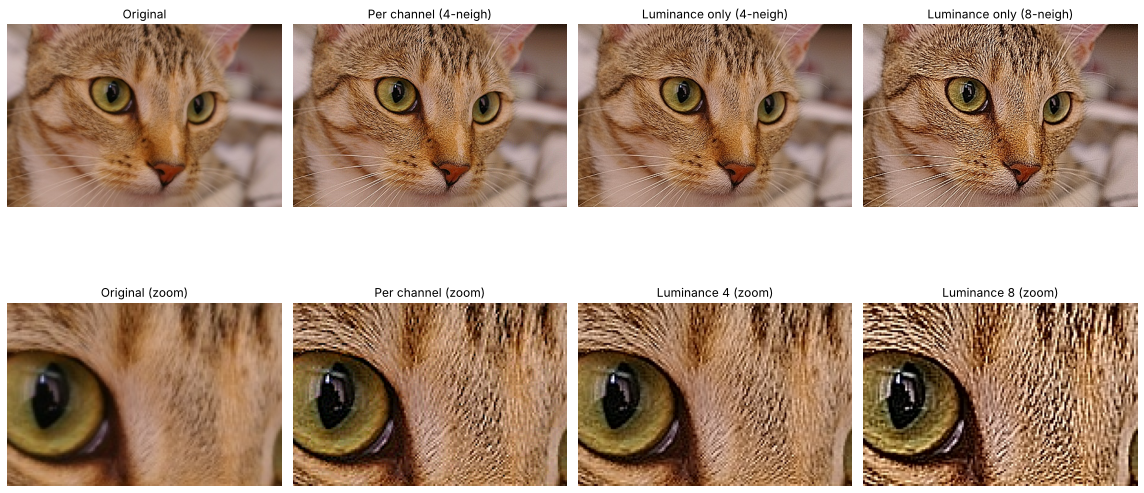

In [7]:
# ================== ( Laplacian on Luminance only ) ===============

# only touch Y (brightness), leave Cr/Cb alone so colours stay the same
def laplacian_sharpen_luma(rgb, kernel):
    ycrcb = cv2.cvtColor(rgb, cv2.COLOR_RGB2YCrCb)
    Y, Cr, Cb = cv2.split(ycrcb)

    Yf = Y.astype(np.float64)
    lapY = cv2.filter2D(Yf, -1, kernel)
    Y_sharp = np.clip(Yf - lapY, 0, 255).astype(np.uint8)

    return cv2.cvtColor(cv2.merge([Y_sharp, Cr, Cb]), cv2.COLOR_YCrCb2RGB)

kernel_4 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)
kernel_8 = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], np.float32)

luma4 = laplacian_sharpen_luma(img_rgb, kernel_4)
luma8 = laplacian_sharpen_luma(img_rgb, kernel_8)

# crop the face, hard to see the difference on the full pic
h, w = img_rgb.shape[:2]
crop = (slice(h // 5, h // 5 + h // 3), slice(w // 3, w // 3 + w // 3))

plt.figure(figsize=(16, 9))
plt.subplot(241), plt.imshow(img_rgb), plt.title('Original')
plt.subplot(242), plt.imshow(sharp_rgb), plt.title('Per channel (4-neigh)')
plt.subplot(243), plt.imshow(luma4), plt.title('Luminance only (4-neigh)')
plt.subplot(244), plt.imshow(luma8), plt.title('Luminance only (8-neigh)')
plt.subplot(245), plt.imshow(img_rgb[crop]), plt.title('Original (zoom)')
plt.subplot(246), plt.imshow(sharp_rgb[crop]), plt.title('Per channel (zoom)')
plt.subplot(247), plt.imshow(luma4[crop]), plt.title('Luminance 4 (zoom)')
plt.subplot(248), plt.imshow(luma8[crop]), plt.title('Luminance 8 (zoom)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


## Observations (RGB)

- `cv2.filter2D`, `cv2.GaussianBlur` and `cv2.Laplacian` accept a 3-channel image and filter each channel independently, so the grayscale code works on RGB with no change except loading the image in colour.
- The `|Laplacian|` image is now coloured: an edge that exists only in one channel (for example a red-to-green border with the same brightness) shows up in that channel's colour.
- The `img + |lap|` step has the same uint8 overflow problem as in grayscale, now in each channel separately, which produces wrongly coloured pixels where one channel wraps and the others don't. The correct result is `f - lap` in float, clipped to 0..255.
- Sharpening only the Y channel gives the same visible sharpness on the fur and whiskers but keeps the original colours, with no coloured fringes. The 8-neighbour kernel gives the strongest sharpening, as in the grayscale case.